# 03 — New feature groups: overload history, university calendar, better ridership

**Question.** Do three new feature groups improve on the round-2 models?
- **Overload history:** recent overloads on the same route + period.
- **University calendar:** term weeks, breaks and exams.
- **Better ridership:** peak half-hour, peak direction, year-over-year change, busier-than-usual ratio.

Everything else is unchanged from round 2:
- same panel rows (2022+, top 10 routes, non-holiday weekdays × 4 periods);
- same split: **train 2022–2024 · validation 2025 · test 2026 (Jan–Oct)**;
- same metrics: PR-AUC, recall in the top 5% and 10%, and paired day-bootstrap 95% CIs for differences.

Code: `src/features.py` (features → `panel_features.parquet`) and `src/round3.py` (ablation).

**About the test set — read this.** The 2026 test set was already looked at once, in round 2 (`02_models.ipynb`).
- The round-3 feature sets and all settings were chosen on **2025 only**. The final model was the one with the highest validation PR-AUC, a rule fixed before the test run.
- Each round-3 feature set was then evaluated on 2026 **exactly once** (`python src/round3.py --test`). Its predictions were saved to `reports/r3_test_scores.parquet`, and the script refuses to run the test stage again.
- This notebook only *reads* those saved predictions; it never refits on or predicts 2026.
- Because we have now looked at 2026 twice, it is a little less "unseen" than in round 2. But nothing in round 3 was tuned on it.

**No leakage.** Every new feature uses only information from *before* the predicted day.
- Look-backs run over the panel's own date grid (weekdays without holidays), so a holiday never counts as "last week" or "yesterday".
- The overload-history features were checked against an independent recomputation on 300 random rows, with 0 mismatches.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from sklearn.metrics import average_precision_score, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import train as T, round3 as R
from features import HIST, CAL, RIDE
warnings.simplefilter("ignore")
REP, FIG = ROOT / "reports", ROOT / "reports" / "figures"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF, GRAY = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#a3a29b"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110, "font.size": 10,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); print("saved", FIG / f"{name}.png")
pd.set_option("display.width", 220)

df = R.load()
print(f"panel_features: {df.shape}; rows by split:", df.split.value_counts().to_dict())
run = json.loads((REP / "r3_test_run.json").read_text()); run

panel_features: (48080, 46); rows by split: {'train': 29800, 'val': 9960, 'test': 8320}


{'run_at': '2026-11-08T13:32:30',
 'best_on_validation': 'LightGBM F_all3_weather',
 'trained_on': '2022-2024',
 'note': 'single evaluation of the round-3 feature sets on 2026'}

## 1. The new features

| Group | Feature | Definition (all look-backs over non-holiday weekdays, same route + period) |
|---|---|---|
| Overload history | `ovl_days_prev5` | weekdays with ≥1 overload among the previous 5 weekdays (0–5) |
| | `ovl_weeks_prev4_sameday` | overload weeks among the previous 4 same-weekday dates (0–4) |
| | `days_since_ovl` | calendar days since the last overload before today, capped at 60 |
| University calendar | `in_term` | 1 on class days (fall or winter term, excluding study breaks) |
| | `week_of_term` | 1, 2, 3 … from the first day of classes (keeps counting through the break), 0 outside the class period |
| | `is_first3w_fall` | 1 in the first 3 weeks of fall classes |
| | `is_break`, `is_exam` | 1 during the fall/winter study break / the exam period |
| Better ridership | `peak_hh_lag1w`, `peak_hh_mean4w` | busiest half-hour (both directions) in the period: 1 week ago / mean of the previous 4 weeks |
| | `peakdir_lag1w`, `peakdir_mean4w` | boardings in the busier direction (Ind or Oud): 1 week ago / 4-week mean |
| | `yoy_ratio` | 4-week mean ÷ the same 4-week mean 52 weeks earlier (clipped to 0.25–4) |
| | `lag_ratio` | 1-week lag ÷ 4-week mean: busier than usual? (clipped to 0.25–4) |
| | (`boardings_lag1w`, `boardings_mean4w`) | the round-2 lags, kept in set D because the ratios build on them |

**Feature sets:** A = route, period, weekday, month · B = A + history · C = A + calendar · D = A + ridership · E = A + all three · F = E + weather.

**Academic calendar** (`data/external/academic_calendar.csv`). The dates are Dalhousie's, used as a proxy for all Halifax universities, whose terms start the same week.
- 2021-22 to 2025-26 come from Dal's official undergraduate calendar PDFs (Academic Dates section); 2026-27 from Dal's Important Dates page.
- Saint Mary's dates were not added.
- Rows marked `CHECK` need a human look (below). One is the **Aug 20 – Sep 18, 2025 faculty lockout**: most fall 2025 classes did not run until Sep 23. The official dates are used anyway, as decided.

In [2]:
cal = pd.read_csv(ROOT / "data" / "external" / "academic_calendar.csv")
print("dates to check:")
display(cal[cal.note.fillna("").str.startswith("CHECK")][["academic_year", "event", "start_date", "end_date", "note"]])
cal.pivot_table(index="academic_year", columns="event", values="start_date", aggfunc="first")[
    ["fall_classes", "fall_break", "fall_exams", "winter_classes", "winter_break", "winter_exams"]]

dates to check:


,academic_year,event,start_date,end_date,note
3,2021-22,winter_classes,2022-01-05,2022-04-06,CHECK: Jan 2022 classes may have started onlin...
24,2025-26,fall_classes,2025-09-02,2025-12-10,CHECK: faculty (DFA) lockout Aug 20-Sep 18 202...
30,2026-27,fall_classes,2026-09-08,2026-12-09,"CHECK: start confirmed; no ""classes end"" entry..."


event,fall_classes,fall_break,fall_exams,winter_classes,winter_break,winter_exams
academic_year,,,,,,
2021-22,2021-09-07,2021-11-08,2021-12-09,2022-01-05,2022-02-21,2022-04-08
2022-23,2022-09-06,2022-11-07,2022-12-09,2023-01-09,2023-02-20,2023-04-13
2023-24,2023-09-05,2023-11-13,2023-12-08,2024-01-08,2024-02-19,2024-04-11
2024-25,2024-09-03,2024-11-11,2024-12-06,2025-01-06,2025-02-17,2025-04-09
2025-26,2025-09-02,2025-11-10,2025-12-11,2026-01-07,2026-02-16,2026-04-11
2026-27,2026-09-08,2026-11-09,2026-12-11,2027-01-11,2027-02-15,2027-04-15


## 2. Is there signal? (training years 2022–2024 only)

saved C:\Users\user\Desktop\ML project\reports\figures\15_r3_feature_signal.png


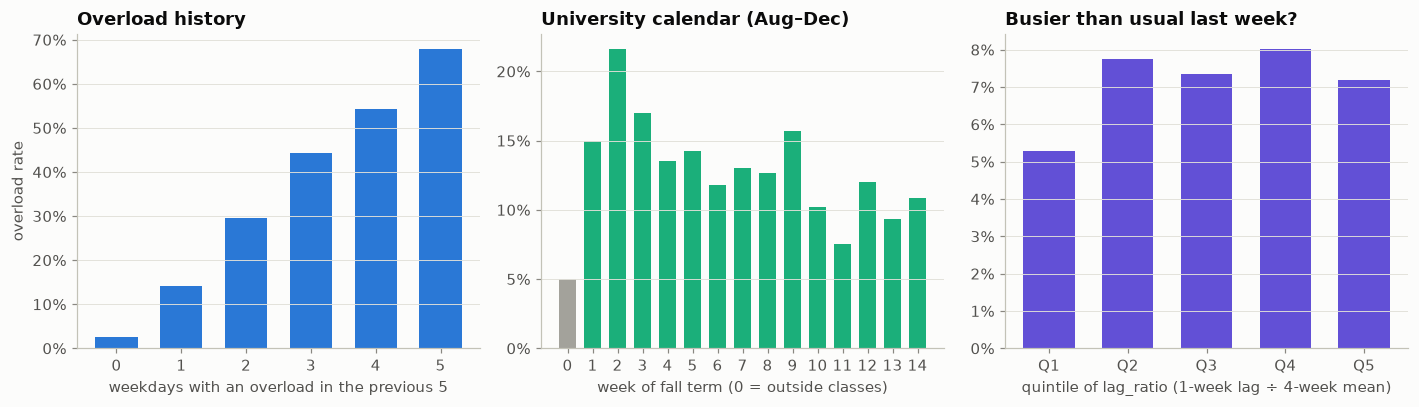

In [3]:
t = df[df.split == "train"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
r = t.groupby("ovl_days_prev5").y.mean()
axes[0].bar(r.index.astype(int).astype(str), r.values, width=0.65, color=SERIES[0])
axes[0].set_title("Overload history"); axes[0].set_xlabel("weekdays with an overload in the previous 5")
f = t[t.month.between(8, 12)]
r = f.groupby("week_of_term").y.mean()
axes[1].bar(r.index.astype(int).astype(str), r.values, width=0.65, color=[GRAY if w == 0 else SERIES[2] for w in r.index])
axes[1].set_title("University calendar (Aug–Dec)"); axes[1].set_xlabel("week of fall term (0 = outside classes)")
r = t.groupby(pd.qcut(t.lag_ratio, 5), observed=True).y.mean()
axes[2].bar([f"Q{i+1}" for i in range(len(r))], r.values, width=0.65, color=SERIES[6])
axes[2].set_title("Busier than usual last week?"); axes[2].set_xlabel("quintile of lag_ratio (1-week lag ÷ 4-week mean)")
for a in axes: a.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[0].set_ylabel("overload rate")
fig.tight_layout(); save(fig, "15_r3_feature_signal"); plt.show()

Raw signal, without controlling for route, period or month:
- **Overload history** is very strong: the rate goes from about 3% with no recent overloads to about 68% with an overload on all of the last 5 weekdays.
- **The fall term start** is visible, but it overlaps almost entirely with `month = 9`, which the baseline already has.
- **"Busier than usual"** (`lag_ratio`) shows little raw signal.

## 3. Validation 2025: choosing features and settings

In [4]:
val = pd.read_csv(REP / "r3_val_results.csv")
cols = ["model", "pr_auc", "roc_auc", "recall_top5", "recall_top10", "recall_day5", "params"]
display(val[cols].round(4))
print("LightGBM seed stability (validation PR-AUC over 5 seeds):")
display(pd.read_csv(REP / "r3_val_seed_stability.csv").round(4))

,model,pr_auc,roc_auc,recall_top5,recall_top10,recall_day5,params
0,Baseline: hist rate,0.3207,0.8225,0.2088,0.3882,0.2004,NaN
1,Baseline: last week,0.1647,0.6215,0.1605,0.3179,0.1490,NaN
2,LogReg A_time,0.3703,0.8413,0.2434,0.4250,0.2120,"{""C"": 0.01, ""interact"": true}"
3,LightGBM A_time,0.3721,0.8481,0.2340,0.4155,0.2141,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
4,LogReg B_history,0.3923,0.8532,0.2497,0.4481,0.2319,"{""C"": 1.0, ""interact"": false}"
5,LightGBM B_history,0.3924,0.8580,0.2602,0.4470,0.2256,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
6,LogReg C_calendar,0.3636,0.8408,0.2361,0.4166,0.2120,"{""C"": 0.01, ""interact"": true}"
7,LightGBM C_calendar,0.3641,0.8504,0.2246,0.4176,0.2109,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
8,LogReg D_ridership,0.3706,0.8445,0.2445,0.4187,0.2130,"{""C"": 0.01, ""interact"": true}"
9,LightGBM D_ridership,0.3707,0.8487,0.2277,0.4166,0.2046,"{""num_leaves"": 7, ""min_child_samples"": 100, ""n..."


LightGBM seed stability (validation PR-AUC over 5 seeds):


,feature_set,mean,sd
0,A_time,0.3710,0.0009
1,B_history,0.3916,0.0008
2,C_calendar,0.3635,0.0015
3,D_ridership,0.3683,0.0014
4,E_all3,0.3897,0.0023
5,F_all3_weather,0.3956,0.0023


In [5]:
gv = pd.read_csv(REP / "r3_val_gains_vs_A.csv")
gv.pivot_table(index="model", columns="metric", values=["diff", "ci_low", "ci_high"]).round(3)

ci_high                              ci_low                                diff                             
metric                   PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5%
model                                                                                                                               
LightGBM B_history        0.042          0.060         0.048  0.000          0.007         0.005  0.020          0.033         0.027
LightGBM C_calendar       0.000          0.024         0.010 -0.018         -0.010        -0.021 -0.008          0.003        -0.008
LightGBM D_ridership      0.015          0.029         0.015 -0.017         -0.021        -0.020 -0.001          0.002        -0.005
LightGBM E_all3           0.046          0.064         0.038 -0.002          0.007        -0.010  0.022          0.035         0.013
LightGBM F_all3_weather   0.051          0.067         0.045  0.002          0.014        -0.002  0.027          0.042         0.020
LogReg B_history          0.041          0.050         0.027  0.004          0.002        -0.011  0.022          0.023         0.006
LogReg C_calendar         0.001          0.008         0.004 -0.015         -0.020        -0.019 -0.007         -0.008        -0.007
LogReg D_ridership        0.013          0.014         0.019 -0.014         -0.030        -0.016  0.000         -0.006         0.001
LogReg E_all3             0.039          0.048         0.022 -0.002         -0.004        -0.019  0.018          0.021         0.002
LogReg F_all3_weather     0.044          0.050         0.030  0.003         -0.004        -0.010  0.023          0.019         0.010

**Selection (fixed before the test run):** the model with the highest validation PR-AUC.
- That is **LightGBM F (all three groups + weather)**: 0.399, with a seed mean of 0.396 ± 0.002.
- Its settings are 15 leaves, min 100 samples per leaf and 200 trees.
- The other feature sets keep their own validation-tuned settings for the ablation.

## 4. Test 2026: single evaluation (read from the saved predictions)

In [6]:
te_scores = pd.read_parquet(REP / "r3_test_scores.parquet")
va_scores = pd.read_parquet(REP / "r3_val_scores.parquet")
test = pd.read_csv(REP / "r3_test_results.csv")
display(test[["model", "pr_auc", "roc_auc", "recall_top5", "incidents_top5", "recall_top10", "recall_day5"]].round(4))
gt = pd.read_csv(REP / "r3_test_gains_vs_A.csv")
gt.pivot_table(index="model", columns="metric", values=["diff", "ci_low", "ci_high"]).round(3)

,model,pr_auc,roc_auc,recall_top5,incidents_top5,recall_top10,recall_day5
0,Baseline: hist rate,0.2487,0.8035,0.2058,0.2369,0.3826,0.2027
1,Baseline: last week,0.1415,0.6148,0.1966,0.2114,0.3064,0.1448
2,LogReg A_time,0.2828,0.8236,0.2530,0.3013,0.3796,0.1936
3,LightGBM A_time,0.2919,0.8323,0.2424,0.2868,0.3933,0.2088
4,LogReg B_history,0.3652,0.8507,0.3064,0.3730,0.4695,0.2698
5,LightGBM B_history,0.3605,0.8528,0.2912,0.3512,0.4680,0.2591
6,LogReg C_calendar,0.2918,0.8240,0.2515,0.2916,0.3857,0.1936
7,LightGBM C_calendar,0.2989,0.8360,0.2530,0.2953,0.3948,0.1890
8,LogReg D_ridership,0.2695,0.8226,0.2256,0.2685,0.3811,0.1997
9,LightGBM D_ridership,0.2897,0.8253,0.2332,0.2722,0.3796,0.1997


ci_high                              ci_low                                diff                             
metric                   PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5%
model                                                                                                                               
LightGBM B_history        0.094          0.100         0.074  0.044          0.034         0.022  0.069          0.075         0.049
LightGBM C_calendar       0.025          0.015         0.026 -0.006         -0.020        -0.013  0.008         -0.002         0.011
LightGBM D_ridership      0.019          0.008         0.013 -0.019         -0.039        -0.033 -0.002         -0.014        -0.009
LightGBM E_all3           0.102          0.101         0.076  0.045          0.036         0.020  0.074          0.075         0.050
LightGBM F_all3_weather   0.107          0.107         0.081  0.049          0.042         0.021  0.078          0.076         0.053
LogReg B_history          0.105          0.118         0.080  0.059          0.054         0.029  0.083          0.090         0.053
LogReg C_calendar         0.026          0.020         0.017 -0.004         -0.012        -0.021  0.009          0.005        -0.002
LogReg D_ridership        0.002          0.024        -0.008 -0.028         -0.023        -0.053 -0.013          0.002        -0.027
LogReg E_all3             0.111          0.116         0.082  0.054          0.045         0.025  0.083          0.079         0.053
LogReg F_all3_weather     0.113          0.123         0.074  0.053          0.052         0.019  0.083          0.090         0.047

### Ablation chart: validation vs test, with day-bootstrap 95% CIs

saved C:\Users\user\Desktop\ML project\reports\figures\16_r3_ablation_pr_auc.png


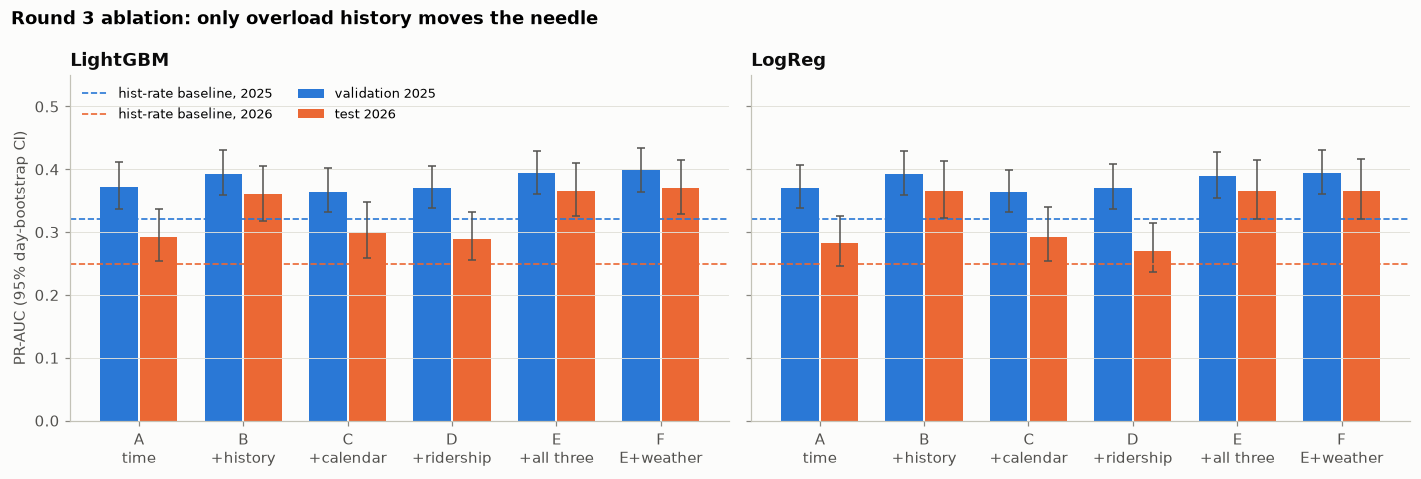

In [7]:
def boot_ap(y, s, dates, n=1000, seed=0):
    rng = np.random.default_rng(seed); u, inv = np.unique(dates, return_inverse=True)
    by = [np.flatnonzero(inv == i) for i in range(len(u))]; out = []
    for _ in range(n):
        k = np.concatenate([by[i] for i in rng.integers(0, len(u), len(u))]); out.append(average_precision_score(y[k], s[k]))
    return np.percentile(out, [2.5, 97.5])

sets = list(R.FEATURE_SETS_R3)
labels = {"A_time": "A\ntime", "B_history": "B\n+history", "C_calendar": "C\n+calendar",
          "D_ridership": "D\n+ridership", "E_all3": "E\n+all three", "F_all3_weather": "F\nE+weather"}
rows = []
for split, sc in [("validation 2025", va_scores), ("test 2026", te_scores)]:
    y, dates = sc.y.to_numpy(), sc.date.to_numpy()
    for fam in R.FAMILIES:
        for fs in sets:
            s = sc[f"{fam} {fs}"].to_numpy(); lo, hi = boot_ap(y, s, dates)
            rows.append({"split": split, "family": fam, "fs": fs, "ap": average_precision_score(y, s), "lo": lo, "hi": hi})
    rows.append({"split": split, "family": "base", "fs": "-", "ap": average_precision_score(y, sc["Baseline: hist rate"]), "lo": np.nan, "hi": np.nan})
abl = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, fam in zip(axes, R.FAMILIES):
    for j, (split, col) in enumerate([("validation 2025", SERIES[0]), ("test 2026", SERIES[1])]):
        s = abl[(abl.family == fam) & (abl.split == split)]
        x = np.arange(len(sets)) + (j - 0.5) * 0.38
        ax.bar(x, s.ap, width=0.36, color=col, label=split)
        ax.errorbar(x, s.ap, yerr=[s.ap - s.lo, s.hi - s.ap], fmt="none", ecolor=INK2, elinewidth=1, capsize=2.5)
        b = abl[(abl.family == "base") & (abl.split == split)].ap.iat[0]
        ax.axhline(b, color=col, ls="--", lw=1.1, label=f"hist-rate baseline, {split[-4:]}")
    ax.set_xticks(range(len(sets)), [labels[k] for k in sets]); ax.set_title(fam); ax.set_ylim(0, 0.55)
axes[0].set_ylabel("PR-AUC (95% day-bootstrap CI)"); axes[0].legend(ncol=2, fontsize=8.5, loc="upper left")
fig.suptitle("Round 3 ablation: only overload history moves the needle", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "16_r3_ablation_pr_auc"); plt.show()

### Gain over A for each feature group (LightGBM)

saved C:\Users\user\Desktop\ML project\reports\figures\17_r3_gains_vs_A.png


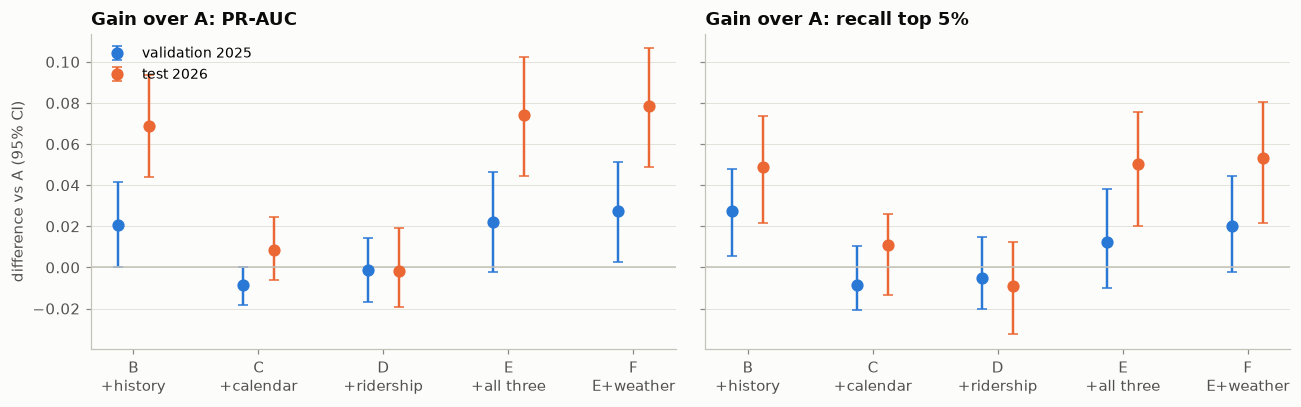

In [8]:
g = pd.concat([gv.assign(split="validation 2025"), gt.assign(split="test 2026")])
g = g[g.model.str.startswith("LightGBM")].assign(fs=lambda d: d.model.str.split(" ", n=1).str[1])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, metric in zip(axes, ["PR-AUC", "recall top 5%"]):
    for j, (split, col) in enumerate([("validation 2025", SERIES[0]), ("test 2026", SERIES[1])]):
        s = g[(g.metric == metric) & (g.split == split)].set_index("fs").reindex(sets[1:])
        x = np.arange(len(s)) + (j - 0.5) * 0.25
        ax.errorbar(x, s["diff"], yerr=[s["diff"] - s.ci_low, s.ci_high - s["diff"]], fmt="o", ms=7,
                    color=col, ecolor=col, elinewidth=1.6, capsize=3, label=split)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(len(sets) - 1), [labels[k] for k in sets[1:]])
    ax.set_title(f"Gain over A: {metric}")
axes[0].set_ylabel("difference vs A (95% CI)"); axes[0].legend(fontsize=9, loc="upper left")
fig.tight_layout(); save(fig, "17_r3_gains_vs_A"); plt.show()

### Pairwise checks on the same saved test predictions (no new evaluation)

In [9]:
te = df[df.split == "test"].reset_index(drop=True)
assert (te.date.to_numpy() == te_scores.date.to_numpy()).all()
pairs = [("LightGBM B_history", "LightGBM E_all3"), ("LightGBM E_all3", "LightGBM F_all3_weather"),
         ("LightGBM B_history", "LightGBM F_all3_weather"), ("Baseline: hist rate", "LightGBM F_all3_weather")]
rows = []
for a, b in pairs:
    for split, d, sc in [("validation 2025", df[df.split == "val"].reset_index(drop=True), va_scores), ("test 2026", te, te_scores)]:
        r = T.bootstrap_diff(d, sc[a].to_numpy(), sc[b].to_numpy())
        rows.append({"comparison": f"{b}  vs  {a}", "split": split, **r})
pd.DataFrame(rows).round(4)

,comparison,split,diff,ci_low,ci_high,p_le_0
0,LightGBM E_all3 vs LightGBM B_history,validation 2025,0.0016,-0.0100,0.0114,0.399
1,LightGBM E_all3 vs LightGBM B_history,test 2026,0.0052,-0.0081,0.0192,0.215
2,LightGBM F_all3_weather vs LightGBM E_all3,validation 2025,0.0054,-0.0017,0.0117,0.064
3,LightGBM F_all3_weather vs LightGBM E_all3,test 2026,0.0042,-0.0045,0.0127,0.161
4,LightGBM F_all3_weather vs LightGBM B_history,validation 2025,0.0070,-0.0063,0.0180,0.147
5,LightGBM F_all3_weather vs LightGBM B_history,test 2026,0.0093,-0.0039,0.0236,0.077
6,LightGBM F_all3_weather vs Baseline: hist rate,validation 2025,0.0787,0.0496,0.1059,0.000
7,LightGBM F_all3_weather vs Baseline: hist rate,test 2026,0.1212,0.0914,0.1531,0.000


### Precision–recall on 2026 and what a top-5% flag would catch

saved C:\Users\user\Desktop\ML project\reports\figures\18_r3_pr_curves_test.png


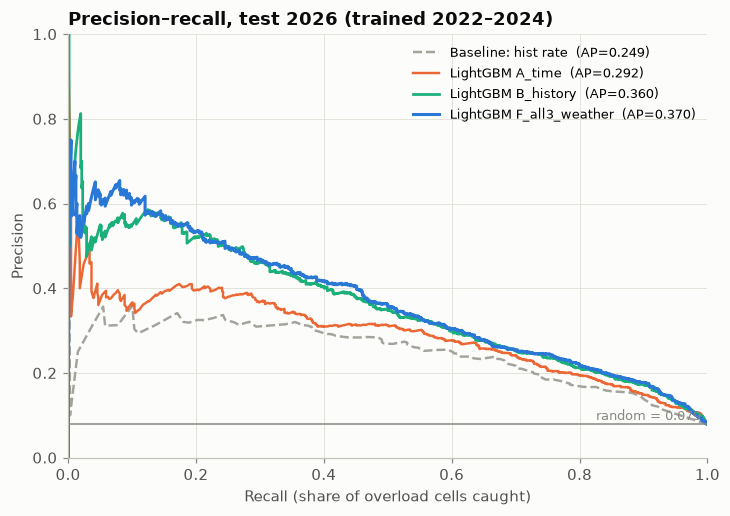

,model,cells flagged,overload cells caught,of,incidents caught,of incidents,precision
0,Baseline: hist rate,416,136,656,194,823,0.327
1,LightGBM A_time,416,159,656,236,823,0.382
2,LightGBM B_history,416,191,656,289,823,0.459
3,LightGBM F_all3_weather,416,194,656,294,823,0.466


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for n, kw in [("Baseline: hist rate", dict(color=GRAY, ls="--", lw=1.6)), ("LightGBM A_time", dict(color=SERIES[1], lw=1.6)),
              ("LightGBM B_history", dict(color=SERIES[2], lw=1.8)), ("LightGBM F_all3_weather", dict(color=SERIES[0]))]:
    pr, rc, _ = precision_recall_curve(te_scores.y, te_scores[n])
    ax.plot(rc, pr, label=f"{n}  (AP={average_precision_score(te_scores.y, te_scores[n]):.3f})", **kw)
ax.axhline(te_scores.y.mean(), color=MUTED, lw=1); ax.text(0.99, te_scores.y.mean() + 0.01, f"random = {te_scores.y.mean():.3f}", ha="right", fontsize=8.5, color=MUTED)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, axis="both"); ax.legend(fontsize=8.5)
ax.set_xlabel("Recall (share of overload cells caught)"); ax.set_ylabel("Precision"); ax.set_title("Precision–recall, test 2026 (trained 2022–2024)")
save(fig, "18_r3_pr_curves_test"); plt.show()

rows = []
for n in ["Baseline: hist rate", "LightGBM A_time", "LightGBM B_history", "LightGBM F_all3_weather"]:
    s = te_scores[n].to_numpy() + 1e-9 * np.random.default_rng(0).random(len(te_scores))
    top = np.argsort(-s, kind="stable")[: int(np.ceil(0.05 * len(s)))]
    rows.append({"model": n, "cells flagged": len(top), "overload cells caught": int(te_scores.y.to_numpy()[top].sum()),
                 "of": int(te_scores.y.sum()), "incidents caught": int(te_scores.n_overloads.to_numpy()[top].sum()),
                 "of incidents": int(te_scores.n_overloads.sum()), "precision": te_scores.y.to_numpy()[top].mean()})
pd.DataFrame(rows).round(3)

## 5. What drives the final model? (SHAP on validation 2025)

saved C:\Users\user\Desktop\ML project\reports\figures\19_r3_shap_best.png


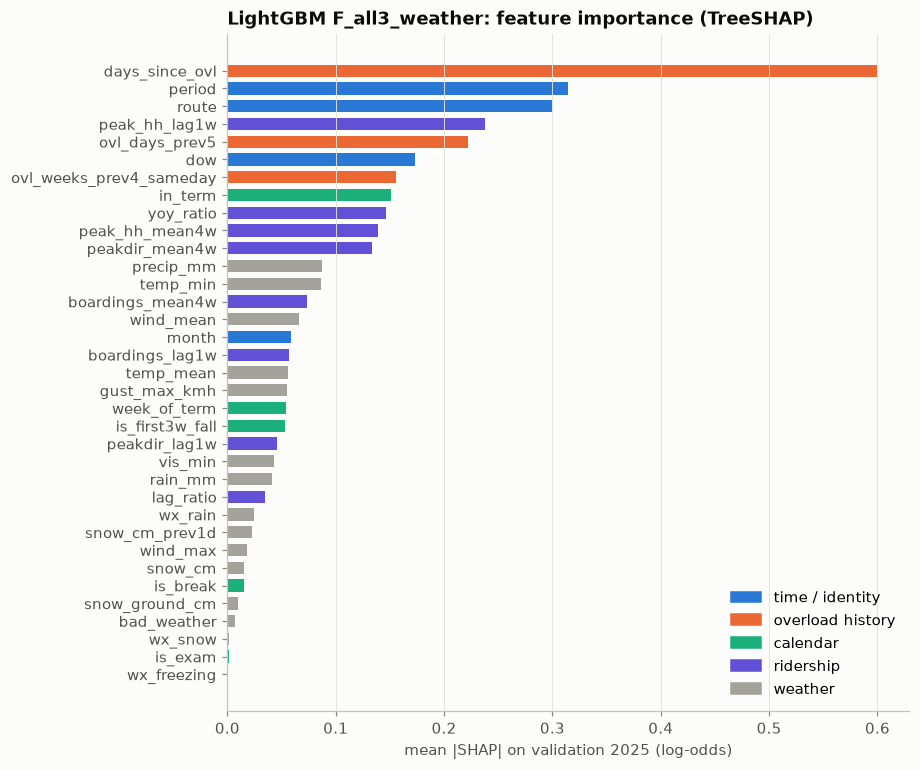

share of total |SHAP| by group: {'overload history': 0.28, 'ridership': 0.248, 'time / identity': 0.242, 'weather': 0.153, 'calendar': 0.078}


In [11]:
sel = json.loads((REP / "r3_selection.json").read_text())
best = sel["_best_on_validation"]
m, feats = T.fit_selected(df[df.split == "train"], best, sel[best], R.FEATURE_SETS_R3)   # same fit as the test run
va = df[df.split == "val"]
contrib = m.booster_.predict(va[feats], pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(axis=0), index=feats).sort_values()
grp = {f: ("time / identity" if f in T.TIME else "overload history" if f in HIST else "calendar" if f in CAL
           else "ridership" if f in RIDE else "weather") for f in feats}
gcol = {"time / identity": SERIES[0], "overload history": SERIES[1], "calendar": SERIES[2], "ridership": SERIES[6], "weather": GRAY}
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(imp.index, imp.values, height=0.7, color=[gcol[grp[f]] for f in imp.index])
ax.legend(handles=[Patch(color=c, label=g) for g, c in gcol.items()], loc="lower right")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |SHAP| on validation 2025 (log-odds)"); ax.set_title(f"{best}: feature importance (TreeSHAP)")
save(fig, "19_r3_shap_best"); plt.show()
share = (pd.Series(np.abs(contrib).mean(axis=0), index=feats).groupby(grp).sum() / np.abs(contrib).mean(axis=0).sum()).sort_values(ascending=False)
print("share of total |SHAP| by group:", share.round(3).to_dict())

## 6. Summary (round 3, 2026-11-08)

**Which feature groups helped?** Only overload history.

| Feature group (LightGBM, added to A) | Validation 2025: PR-AUC gain [95% CI] | Test 2026: PR-AUC gain [95% CI] | Verdict |
|---|---|---|---|
| B. Overload history | +0.020 [+0.000, +0.042] | **+0.069 [+0.044, +0.094]** | helps (logistic regression: +0.022 / +0.083) |
| C. University calendar | −0.008 [−0.018, +0.000] | +0.008 [−0.006, +0.025] | no reliable gain |
| D. Better ridership | −0.001 [−0.017, +0.015] | −0.002 [−0.019, +0.019] | no gain |
| E. All three | +0.022 [−0.002, +0.046] | +0.074 [+0.045, +0.102] | = history (E vs B on test: +0.005 [−0.008, +0.019]) |
| F. E + weather | +0.027 [+0.002, +0.051] | +0.078 [+0.049, +0.107] | weather adds nothing on top (F vs E: +0.004 [−0.005, +0.013]) |

- **The calendar's raw signal is real but already covered.** The first weeks of fall term have a 15–22% overload rate vs 5% outside classes, but the term start coincides with `month = 9`, which A already has.
- **The better ridership features add nothing.** They take 25% of the final model's SHAP importance, yet improve nothing: they mostly restate how busy each route + period usually is.

**Final model.** Chosen on validation by the pre-set rule (highest PR-AUC): **LightGBM F**.
- On 2026 it reaches **PR-AUC 0.370**, vs 0.292 for round 2's time-only model and 0.249 for the historical-rate rule (+0.121 [+0.091, +0.153]).
- A top-5% flag (416 route-periods) catches **194 of 656 overload cells (30%) and 294 of 823 incidents (36%), at 47% precision**. The round-2 model caught 159 cells, 236 incidents, at 38% precision.
- History alone (LightGBM B: 0.361; F vs B +0.009 [−0.004, +0.024]) does essentially as well and is simpler.

**What this means for "overload risk is mostly structural (where and when) rather than day-to-day demand or weather".**
- **It still holds, with one refinement.** The extra predictive value comes from *where overloads have just been happening*: a route + period that has recently had overloads keeps having them. That looks like a persistent capacity shortfall on particular trips, which is structural, just more local and recent than route × period × month.
- **Day-to-day signals still add nothing:** last week's ridership, peak loads, year-over-year growth, the term calendar beyond the month, and weather.
- **History also tracks the year's overall level.** It helped more on 2026 (whose overload rate fell to 7.9%) than on 2025, so it partly corrects the year-to-year drift a time-only model cannot follow.
- **Caveat:** it may also pick up reporting habits, such as routes or drivers that report more.

**Honesty notes.**
- The 2026 test set was already viewed once, in round 2.
- In round 3, every choice was made on 2025. Each new feature set was evaluated on 2026 once (`src/round3.py --test`), and this notebook only reads those saved predictions.
- The hist-rate baseline catches 136 cells here vs 135 in round 2 because of a different tie-breaking method; its PR-AUC is unchanged.

**Calendar caveats.**
- Dal dates stand in for all Halifax universities; Saint Mary's dates were not added.
- Three dates are flagged `CHECK` in `academic_calendar.csv`: the inferred fall 2026 last class day, the fall 2025 faculty lockout (Aug 20 – Sep 18, 2025, inside the validation year, official dates used), and a possible online start in January 2022.